Import libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib
df= pd.read_csv('/content/drive/MyDrive/Colab Notebooks/data set/Hotel Bookings (1) (4).csv')

Loading the hotel dataset

In [ ]:
df.head(5)

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


Rows and columns of dataset

In [ ]:
df.index

RangeIndex(start=0, stop=119390, step=1)

Project Summary -

This Project was given to us by the Almabetter team with an intention to understand the Business done by Hotel Group. This Dataset had two hotels City Hotel and Resort Hotel.The data provided was for 3 years 2015 , 2016 and 2017.we also have the revenue and booking details with number of days of stay and booking cancellation,total number of guests including children. It also specifies guests wait period for booking , repetation of guests,their food choices among others.The data also gives us an analysation of countries from which bookings have been done. We also a agent and other channels who also help in business by booking rooms for guests on the resort and city hotel behalf. The data is divided between city hotel and resort hotel. Hence we can make a fair comparision between both. Before visualize any data from the data set We will do the data cleaning as to fill any null values and delete any duplicated values and after that we have to do data wrangling. Also we will do our analysis for both city and resort as individual businesses and in comparision to one another. We will also take help of charts for better analysis.

Information of Hotel dataset

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

Duplicated value

In [ ]:
duplicate_value=df.duplicated().value_counts()
duplicate_value

,count
False,87396
True,31994


Understanding your variables

In [ ]:
df.columns

Index(['Booking_ID', 'hotel', 'is_canceled', 'lead_time', 'adults', 'children',
       'babies', 'meal', 'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date', 'Total_People',
       'arrival_date', 'total_stays', 'Satisfaction_Level'],
      dtype='object')

Describe your dataset

In [ ]:
df.describe(include='all')

,Booking_ID,hotel,is_canceled,lead_time,adults,children,babies,meal,country,market_segment,...,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,Total_People,arrival_date,total_stays,Satisfaction_Level
count,87396.0000,87396,87396.000000,87396.000000,87396.000000,87392.000000,87396.000000,87396,87396,87396,...,87396,87396.000000,87396.000000,87396.000000,87396,87396,87396.000000,87396,87396.000000,87396
unique,NaN,2,NaN,NaN,NaN,NaN,NaN,5,178,8,...,4,NaN,NaN,NaN,3,926,NaN,NaN,NaN,2
top,NaN,City Hotel,NaN,NaN,NaN,NaN,NaN,BB,PRT,Online TA,...,Transient,NaN,NaN,NaN,Check-Out,2016-02-14,NaN,NaN,NaN,Satisfied
freq,NaN,53428,NaN,NaN,NaN,NaN,NaN,67978,27453,51618,...,71986,NaN,NaN,NaN,63371,211,NaN,NaN,NaN,74287
mean,43698.5000,NaN,0.274898,79.891368,1.875795,0.138640,0.010824,NaN,NaN,NaN,...,NaN,106.337246,0.084226,0.698567,NaN,NaN,2.025253,2016-09-15 00:20:26.857064448,3.630658,NaN
min,1.0000,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,...,NaN,-6.380000,0.000000,0.000000,NaN,NaN,0.000000,2015-07-01 00:00:00,0.000000,NaN
25%,21849.7500,NaN,0.000000,11.000000,2.000000,0.000000,0.000000,NaN,NaN,NaN,...,NaN,72.000000,0.000000,0.000000,NaN,NaN,2.000000,2016-04-01 00:00:00,2.000000,NaN
50%,43698.5000,NaN,0.000000,49.000000,2.000000,0.000000,0.000000,NaN,NaN,NaN,...,NaN,98.100000,0.000000,0.000000,NaN,NaN,2.000000,2016-09-20 00:00:00,3.000000,NaN
75%,65547.2500,NaN,1.000000,125.000000,2.000000,0.000000,0.000000,NaN,NaN,NaN,...,NaN,134.000000,0.000000,1.000000,NaN,NaN,2.000000,2017-04-01 00:00:00,5.000000,NaN
max,87396.0000,NaN,1.000000,737.000000,55.000000,10.000000,10.000000,NaN,NaN,NaN,...,NaN,5400.000000,8.000000,5.000000,NaN,NaN,55.000000,2017-08-31 00:00:00,69.000000,NaN


Data Wrangling

In [ ]:
#Identify and remove any duplicate records from dataset
df.drop_duplicates(inplace=True)

In [ ]:
print(df.columns)

Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'company', 'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date'],
      dtype='object')


In [ ]:
#Replace null value from country as "unknown"
df['country'] = df['country'].fillna('unknown')

In [ ]:
#Replace null value from agent with "others"
df['agent'] = df['agent'].fillna('others')

There are 95% null records in company column so that i have remove company column

In [ ]:
# Remove column company as 93% null values
df.drop('company', axis=1, inplace=True)

In [ ]:
df.shape[0]
# Before cleaning the data value 119390 rows
# After cleaning the data value 87396 rows

87396

In [ ]:
# merge columns of adult ,children, babies into total people
df['Total_People'] = df[['adults', 'children', 'babies']].fillna(0).sum(axis=1)
print(df.Total_People)

0         2.0
1         2.0
2         1.0
3         1.0
4         2.0
         ... 
119385    2.0
119386    3.0
119387    2.0
119388    2.0
119389    2.0
Name: Total_People, Length: 87396, dtype: float64


In [ ]:
#remove arrival_date_week_number
df.drop('arrival_date_week_number', axis=1, inplace=True)
print(df.columns)

Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_day_of_month',
       'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children',
       'babies', 'meal', 'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date', 'Total_People'],
      dtype='object')


In [ ]:
# Merged 3 columns arrival_date_year,arrival_date_month,arrival_date_day_of_month
df['arrival_date'] = pd.to_datetime(
    df['arrival_date_year'].astype(str) + ' ' +
    df['arrival_date_month'] + ' ' +
    df['arrival_date_day_of_month'].astype(str)
)
df.drop(['arrival_date_year', 'arrival_date_month', 'arrival_date_day_of_month'], axis=1, inplace=True)

In [ ]:
print(df.columns)

Index(['hotel', 'is_canceled', 'lead_time', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date', 'Total_People',
       'arrival_date'],
      dtype='object')


In [ ]:
#Merged column of stays 'stays_in_weekend_nights' & 'stays_in_week_nights'
df['total_stays'] = df['stays_in_weekend_nights'] + df['stays_in_week_nights']
df.drop(['stays_in_weekend_nights', 'stays_in_week_nights'], axis=1, inplace=True)

In [ ]:
print(df.columns)

Index(['hotel', 'is_canceled', 'lead_time', 'adults', 'children', 'babies',
       'meal', 'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date', 'Total_People',
       'arrival_date', 'total_stays'],
      dtype='object')


In [ ]:
#Add primary key as 'Booking ID'
df['Booking_ID'] = range(1, len(df) + 1)
# move the column into first coumn
cols = ['Booking_ID'] + [col for col in df.columns if col != 'Booking_ID']
df = df[cols]

In [ ]:
df.head(10)

,Booking_ID,hotel,is_canceled,lead_time,adults,children,babies,meal,country,market_segment,...,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,Total_People,arrival_date,total_stays
0,1,Resort Hotel,0,342,2,0.0,0,BB,PRT,Direct,...,0,Transient,0.0,0,0,Check-Out,2015-07-01,2.0,2015-07-01,0
1,2,Resort Hotel,0,737,2,0.0,0,BB,PRT,Direct,...,0,Transient,0.0,0,0,Check-Out,2015-07-01,2.0,2015-07-01,0
2,3,Resort Hotel,0,7,1,0.0,0,BB,GBR,Direct,...,0,Transient,75.0,0,0,Check-Out,2015-07-02,1.0,2015-07-01,1
3,4,Resort Hotel,0,13,1,0.0,0,BB,GBR,Corporate,...,0,Transient,75.0,0,0,Check-Out,2015-07-02,1.0,2015-07-01,1
4,5,Resort Hotel,0,14,2,0.0,0,BB,GBR,Online TA,...,0,Transient,98.0,0,1,Check-Out,2015-07-03,2.0,2015-07-01,2
6,6,Resort Hotel,0,0,2,0.0,0,BB,PRT,Direct,...,0,Transient,107.0,0,0,Check-Out,2015-07-03,2.0,2015-07-01,2
7,7,Resort Hotel,0,9,2,0.0,0,FB,PRT,Direct,...,0,Transient,103.0,0,1,Check-Out,2015-07-03,2.0,2015-07-01,2
8,8,Resort Hotel,1,85,2,0.0,0,BB,PRT,Online TA,...,0,Transient,82.0,0,1,Canceled,2015-05-06,2.0,2015-07-01,3
9,9,Resort Hotel,1,75,2,0.0,0,HB,PRT,Offline TA/TO,...,0,Transient,105.5,0,0,Canceled,2015-04-22,2.0,2015-07-01,3
10,10,Resort Hotel,1,23,2,0.0,0,BB,PRT,Online TA,...,0,Transient,123.0,0,0,Canceled,2015-06-23,2.0,2015-07-01,4


In [ ]:
#Added Column Called Satisfaction Level of Customer Using the reserve_room_type+ assign_room_type column
df['Satisfaction_Level'] = (
    df['reserved_room_type'] == df['assigned_room_type']
).map({True: 'Satisfied', False: 'Not Satisfied'})

In [ ]:
print(df.columns)

Index(['Booking_ID', 'hotel', 'is_canceled', 'lead_time', 'adults', 'children',
       'babies', 'meal', 'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date', 'Total_People',
       'arrival_date', 'total_stays', 'Satisfaction_Level'],
      dtype='object')


Understand the relationships between variables through data visualization, storytelling, and chart experimentation.

In [ ]:
#Chart-1  visualization code
hotel_value_count=df['hotel'].value_counts()
hotel_value_count

,count
hotel,
City Hotel,79330
Resort Hotel,40060


Q.1: Which type of hotel have more number of boking[city hotels or resort hotels]

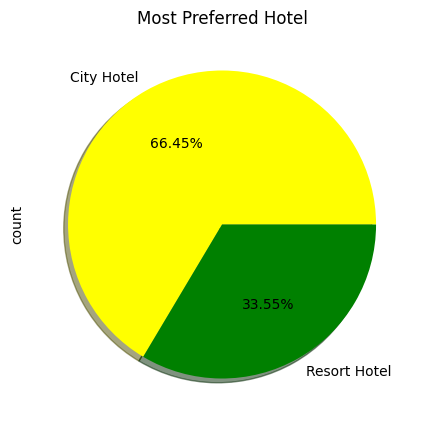

In [ ]:
# Pie chart for most prefferd Hotel
hotel_value_count.plot.pie(
    figsize=(5,5),
    autopct='%1.2f%%',
    shadow=True,
    colors=['yellow', 'green']
)

plt.title('Most Preferred Hotel')
plt.show()

Q.2 Which age group contributes the highest number of bookings

In [ ]:
# Donut Chart
labels = ['Adults', 'Children', 'Babies']
sizes = [
    df['adults'].sum(),
    df['children'].sum(),
    df['babies'].sum()
]

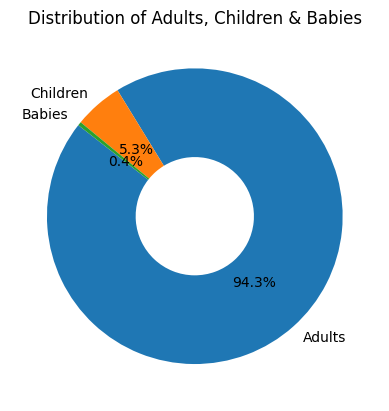

In [ ]:

plt.figure()

plt.pie(
    sizes,
    labels=labels,
    autopct='%1.1f%%',
    startangle=142,
    wedgeprops={'width': 0.6}  #  makes it donut
)

plt.title('Distribution of Adults, Children & Babies')
plt.show()

Q.3 For City Hotel vs Resort Hotel, which year had the most bookings?

<Axes: xlabel='arrival_date_year', ylabel='count'>

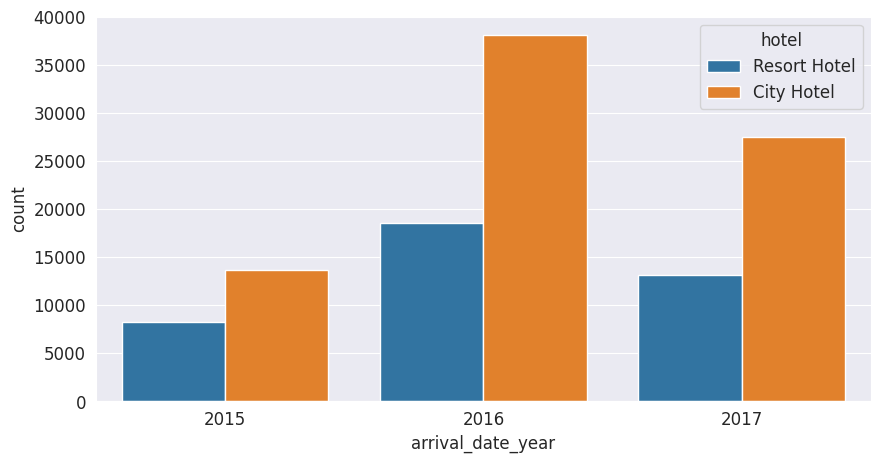

In [ ]:
# Bar chart
sns.set_style('darkgrid')
matplotlib.rcParams['font.size']=12
matplotlib.rcParams['figure.figsize']=(10,5)
matplotlib.rcParams['figure.facecolor']='white'
sns.countplot(x=df['arrival_date_year'],data=df,hue='hotel')

Q.4- Which type of hotel have highest revenue or ADR

Text(0.5, 1.0, 'ADR of Hotel')

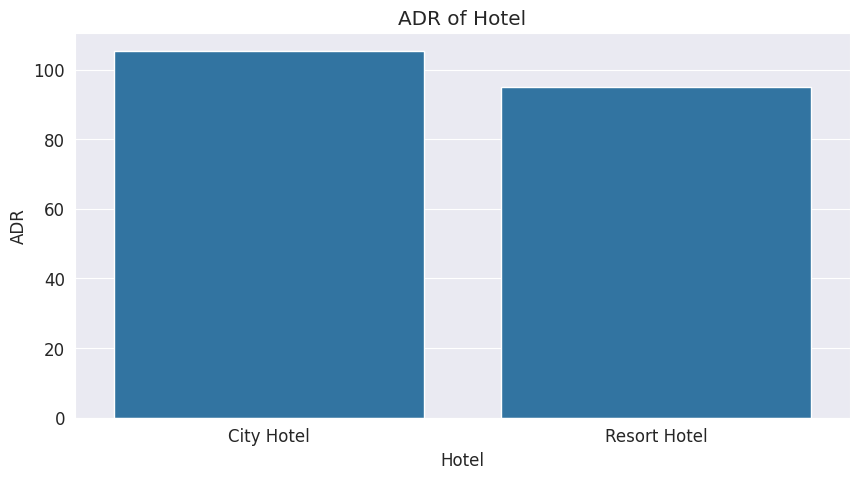

In [ ]:
# Bar chart
#Group by hotel
grup_by_hotel=df.groupby('hotel')

#grouping by hotel adr
highest_adr=grup_by_hotel['adr'].mean().reset_index()

#set plot size
plt.figure(figsize=(10,5))
sns.barplot(x=highest_adr['hotel'],y=highest_adr['adr'])
plt.xlabel('Hotel')
plt.ylabel('ADR')
plt.title('ADR of Hotel')

Q5- What is the percentage of booking cancellation for city hotel and resort hotel

Text(0.5, 1.0, 'Percentage of booking cancellation')

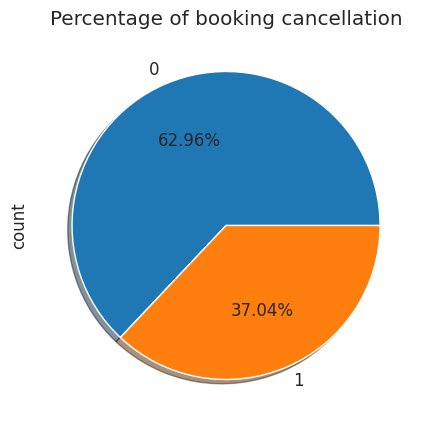

In [ ]:
df['is_canceled'].value_counts().plot.pie(figsize=(5,5),autopct='%1.2f%%',shadow=True)
plt.title('Percentage of booking cancellation')

Q6- Monthwise highest number of booking

In [ ]:
#Chart 7
booking_by_month=df.groupby(['arrival_date_month'])['hotel'].count().reset_index().rename(columns={'hotel':"Counts"})

month_order=['January','February','March','April','May','June','July','August','September','October','November','December']

booking_by_month['arrivel_date_month']=pd.Categorical(booking_by_month['arrival_date_month'])

booking_by_month=booking_by_month.sort_values('arrival_date_month')
booking_by_month

,arrival_date_month,Counts,arrivel_date_month
0,April,11089,April
1,August,13877,August
2,December,6780,December
3,February,8068,February
4,January,5929,January
5,July,12661,July
6,June,10939,June
7,March,9794,March
8,May,11791,May
9,November,6794,November


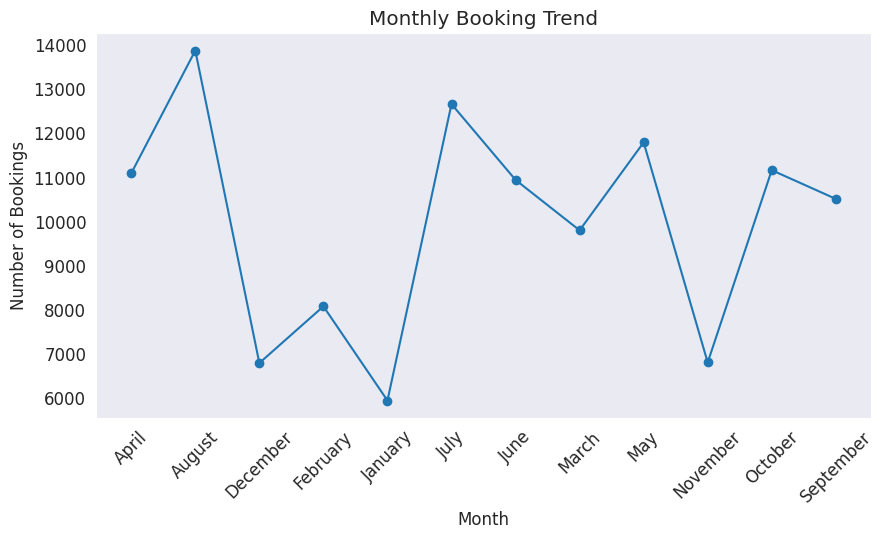

In [ ]:
# Line chart
plt.figure()

plt.plot(
    booking_by_month['arrival_date_month'],
    booking_by_month['Counts'],
    marker='o'
)

plt.xlabel('Month')
plt.ylabel('Number of Bookings')
plt.title('Monthly Booking Trend')

plt.xticks(rotation=45)
plt.grid()

plt.show()

Q.7 What is the count for car parking space requirement.

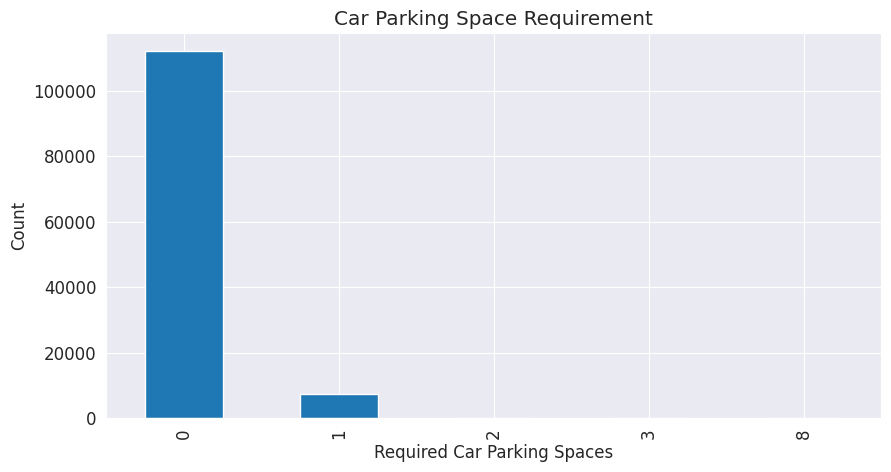

In [ ]:
parking_counts.plot(kind='bar')

plt.xlabel('Required Car Parking Spaces')
plt.ylabel('Count')
plt.title('Car Parking Space Requirement')

plt.show()